In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV , RandomizedSearchCV
from sklearn.metrics import root_mean_squared_error , mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline , make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor , HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer , KNNImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder , OrdinalEncoder



In [3]:
from sklearn.ensemble import AdaBoostRegressor , BaggingRegressor , ExtraTreesRegressor , VotingRegressor , StackingRegressor
from sklearn.preprocessing import StandardScaler , PowerTransformer , Binarizer , KBinsDiscretizer , FunctionTransformer
 



* 1.Downloding the dataset from Kaggle using `opendatsets`library 
* 2.Importing the Dependency
* 3.Performing the `Exploratory Data Analysis` (EDA)
* 4.Using the advanced plotting techniques wit the `Seaborn` library
* 5.Preprocessing the data by building the separate `pipeline` 
* 6.Building the Machine Learning model using different algorithm
* 7.Like `LinearRegression` , `DecicsionTreeRegressor`  , `ExtraTreesRegressor` , `VotingRegressor`,`StackingRegressor`and `RandomForestRegressor`
* 8.Computing the loss using `RMSE` Using the `Cross_validation`
* 9.Tunning the Hyperparameters using automated tunning strategy called `GridSearchCV`



In [4]:
import warnings
warnings.filterwarnings("ignore")

In [5]:
sns.set_style("darkgrid")

In [6]:
import opendatasets as od

In [7]:
od.download("https://www.kaggle.com/datasets/lainguyn123/student-performance-factors")

In [8]:
student_df = pd.read_csv("student-performance-factors/StudentPerformanceFactors.csv")
student_df

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


In [9]:
student_df.iloc[10, 1:]

Attendance                          80
Parental_Involvement               Low
Access_to_Resources               High
Extracurricular_Activities          No
Sleep_Hours                          8
Previous_Scores                     88
Motivation_Level                Medium
Internet_Access                     No
Tutoring_Sessions                    4
Family_Income                   Medium
Teacher_Quality                   High
School_Type                    Private
Peer_Influence                 Neutral
Physical_Activity                    4
Learning_Disabilities               No
Parental_Education_Level       College
Distance_from_Home            Moderate
Gender                            Male
Exam_Score                          68
Name: 10, dtype: object

In [10]:
student_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

In [11]:
student_df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [12]:
student_df.describe(include = 'object')

,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Motivation_Level,Internet_Access,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
count,6607,6607,6607,6607,6607,6607,6529,6607,6607,6607,6517,6540,6607
unique,3,3,2,3,2,3,3,2,3,2,3,3,2
top,Medium,Medium,Yes,Medium,Yes,Low,Medium,Public,Positive,No,High School,Near,Male
freq,3362,3319,3938,3351,6108,2672,3925,4598,2638,5912,3223,3884,3814


In [13]:
student_df.isna().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [14]:
categorical_cols = student_df.select_dtypes(include = 'object').columns.tolist()
numeric_cols = student_df.select_dtypes(include = np.number).columns.tolist()
for col in categorical_cols:
    print(f"-----------{col}---------------")
    print(student_df[col].unique())
    print()

-----------Parental_Involvement---------------
['Low' 'Medium' 'High']

-----------Access_to_Resources---------------
['High' 'Medium' 'Low']

-----------Extracurricular_Activities---------------
['No' 'Yes']

-----------Motivation_Level---------------
['Low' 'Medium' 'High']

-----------Internet_Access---------------
['Yes' 'No']

-----------Family_Income---------------
['Low' 'Medium' 'High']

-----------Teacher_Quality---------------
['Medium' 'High' 'Low' nan]

-----------School_Type---------------
['Public' 'Private']

-----------Peer_Influence---------------
['Positive' 'Negative' 'Neutral']

-----------Learning_Disabilities---------------
['No' 'Yes']

-----------Parental_Education_Level---------------
['High School' 'College' 'Postgraduate' nan]

-----------Distance_from_Home---------------
['Near' 'Moderate' 'Far' nan]

-----------Gender---------------
['Male' 'Female']



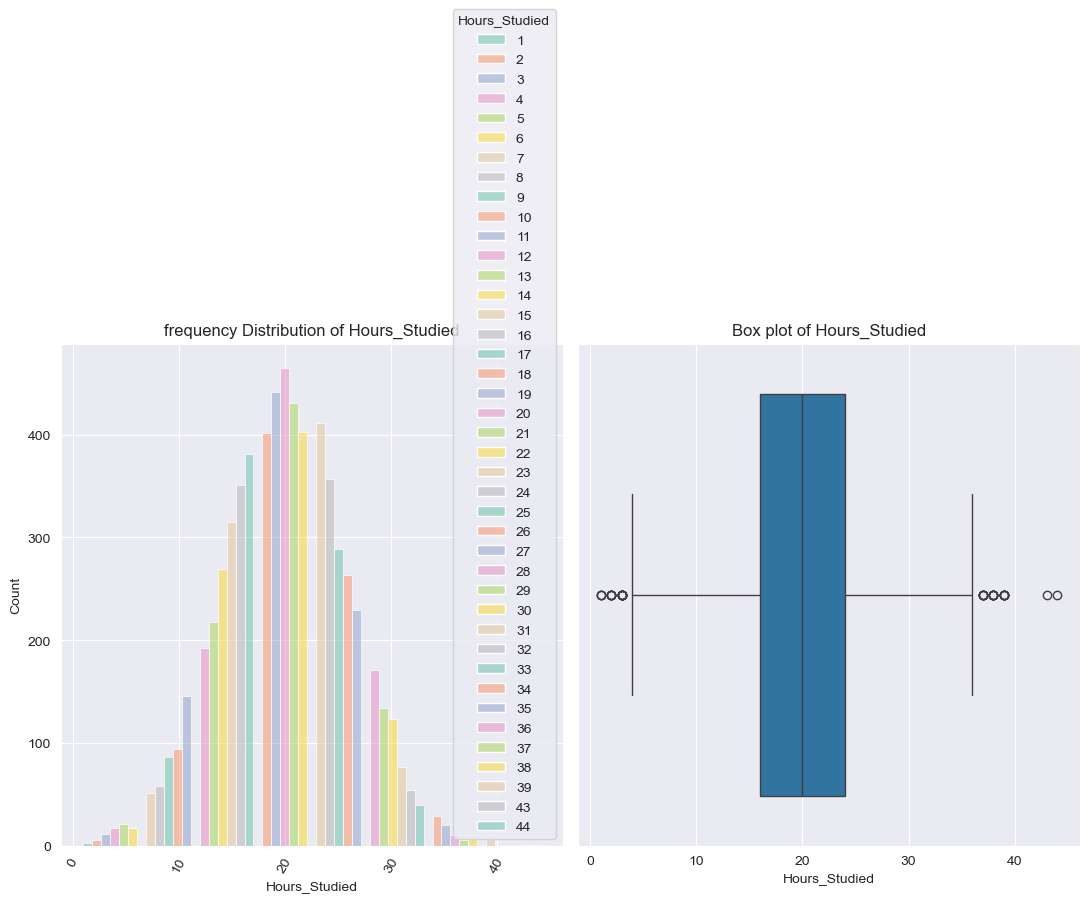

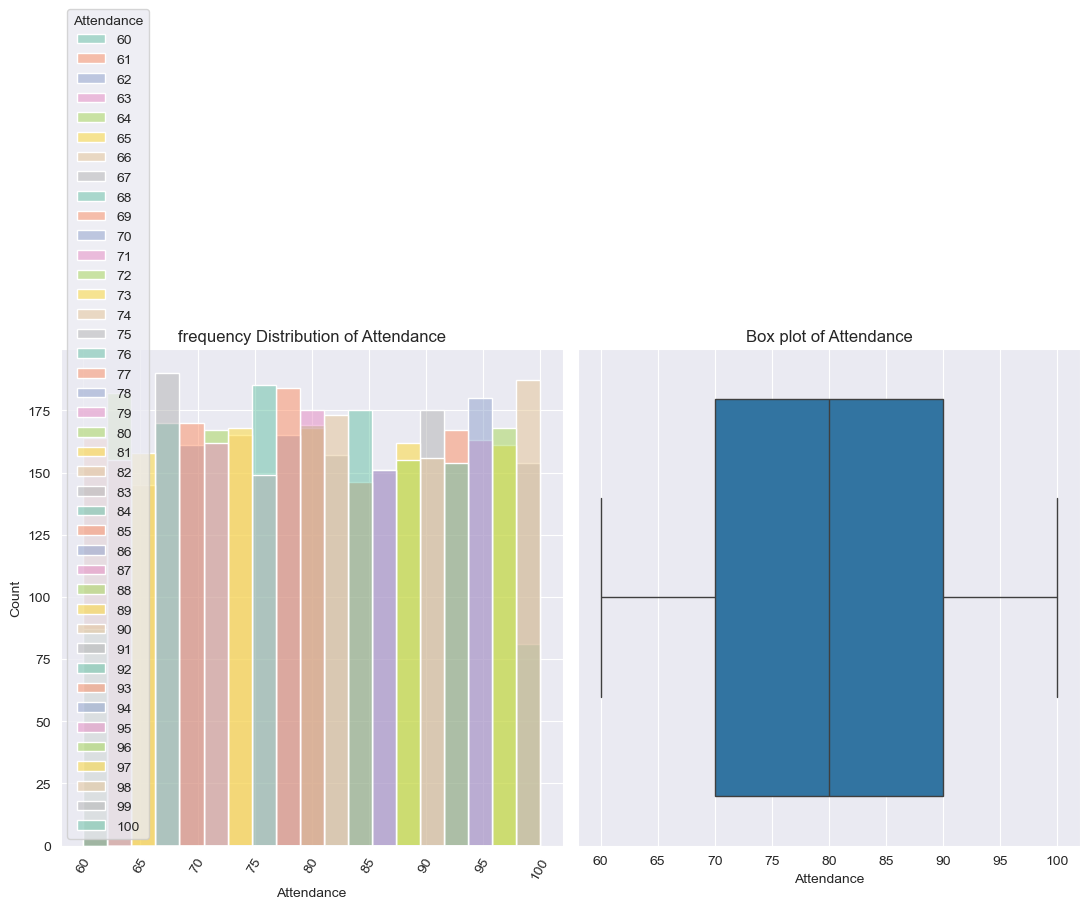

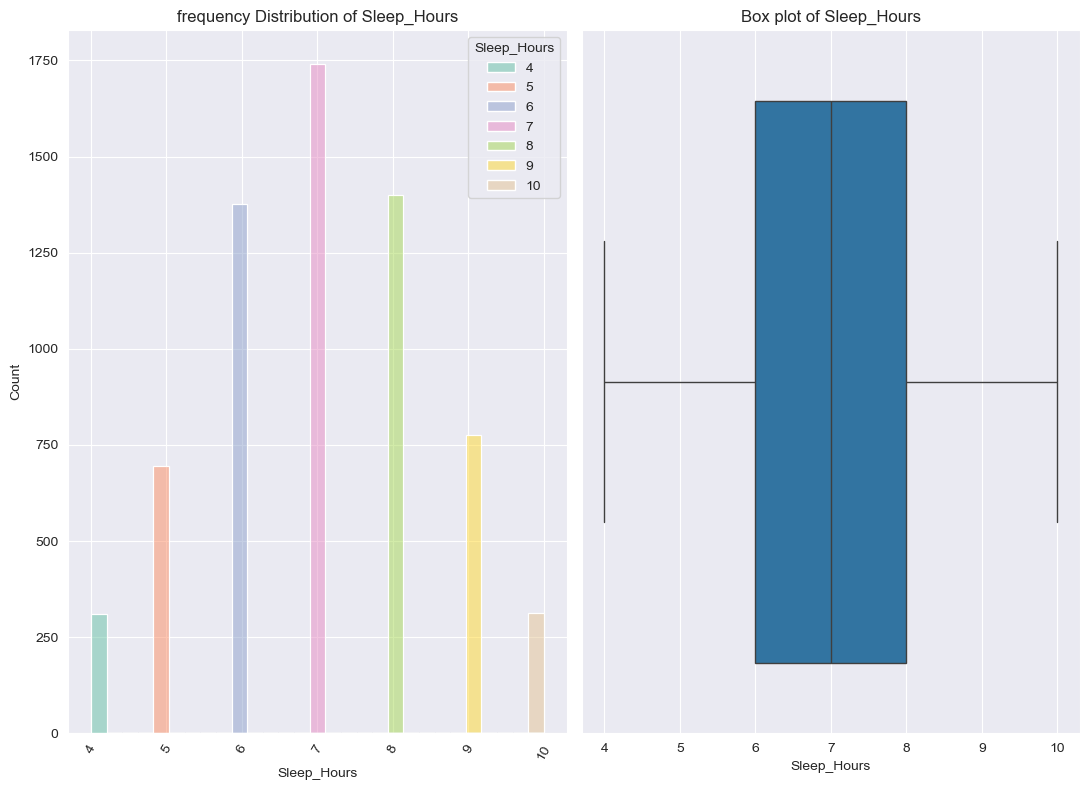

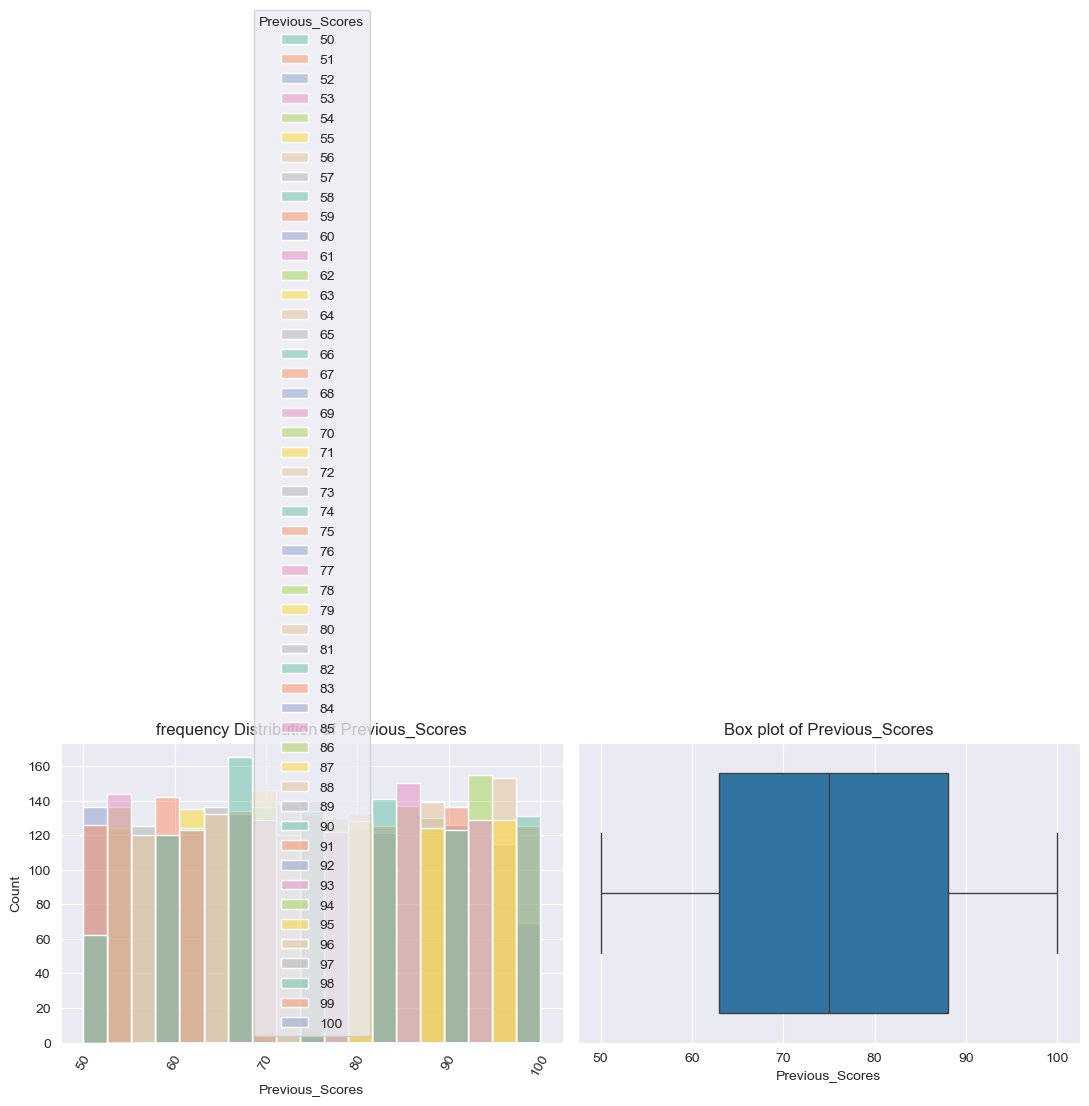

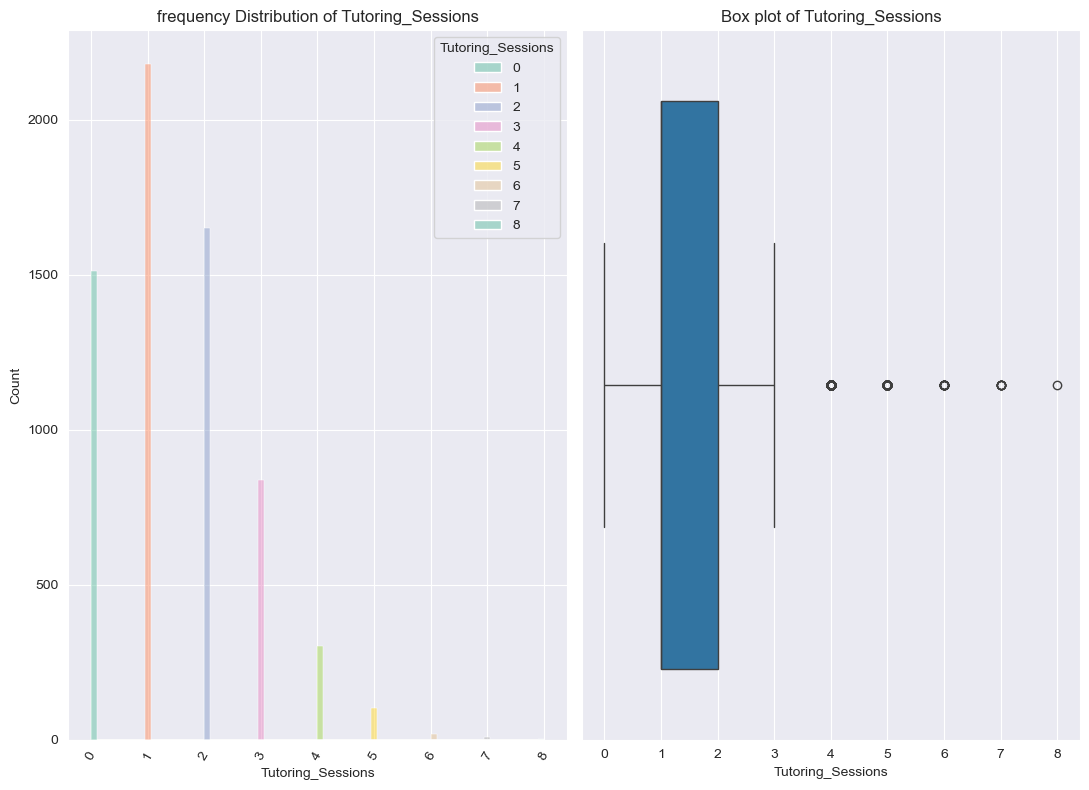

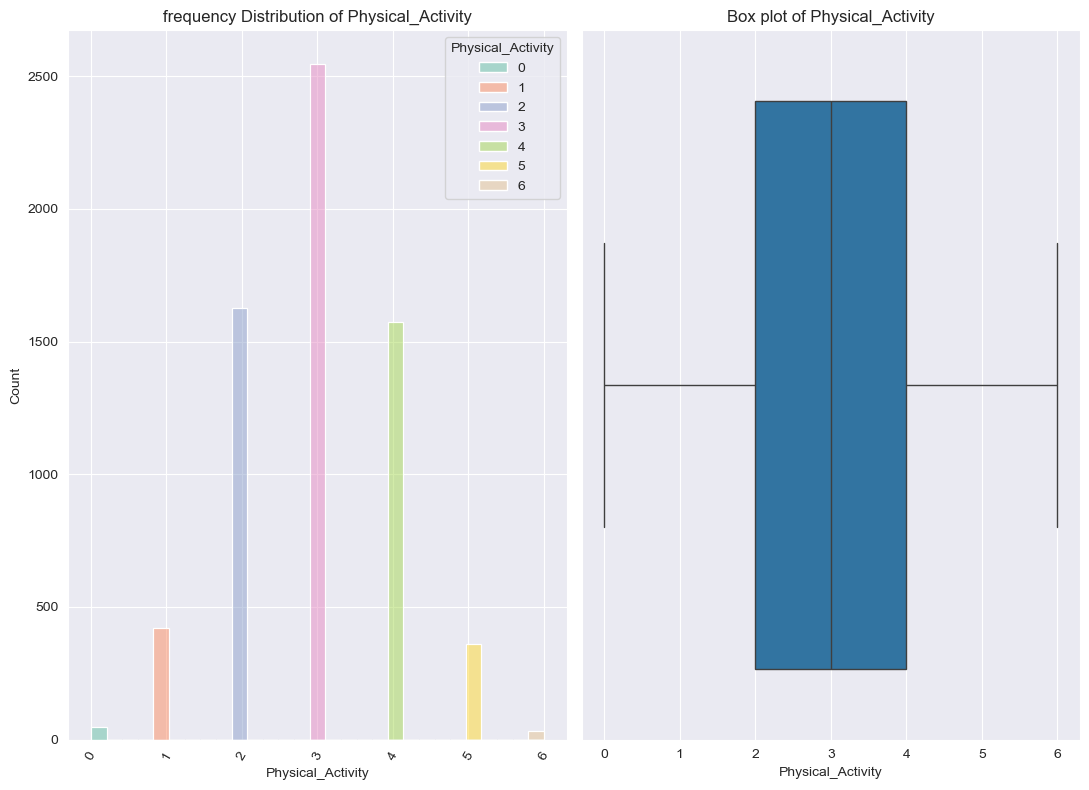

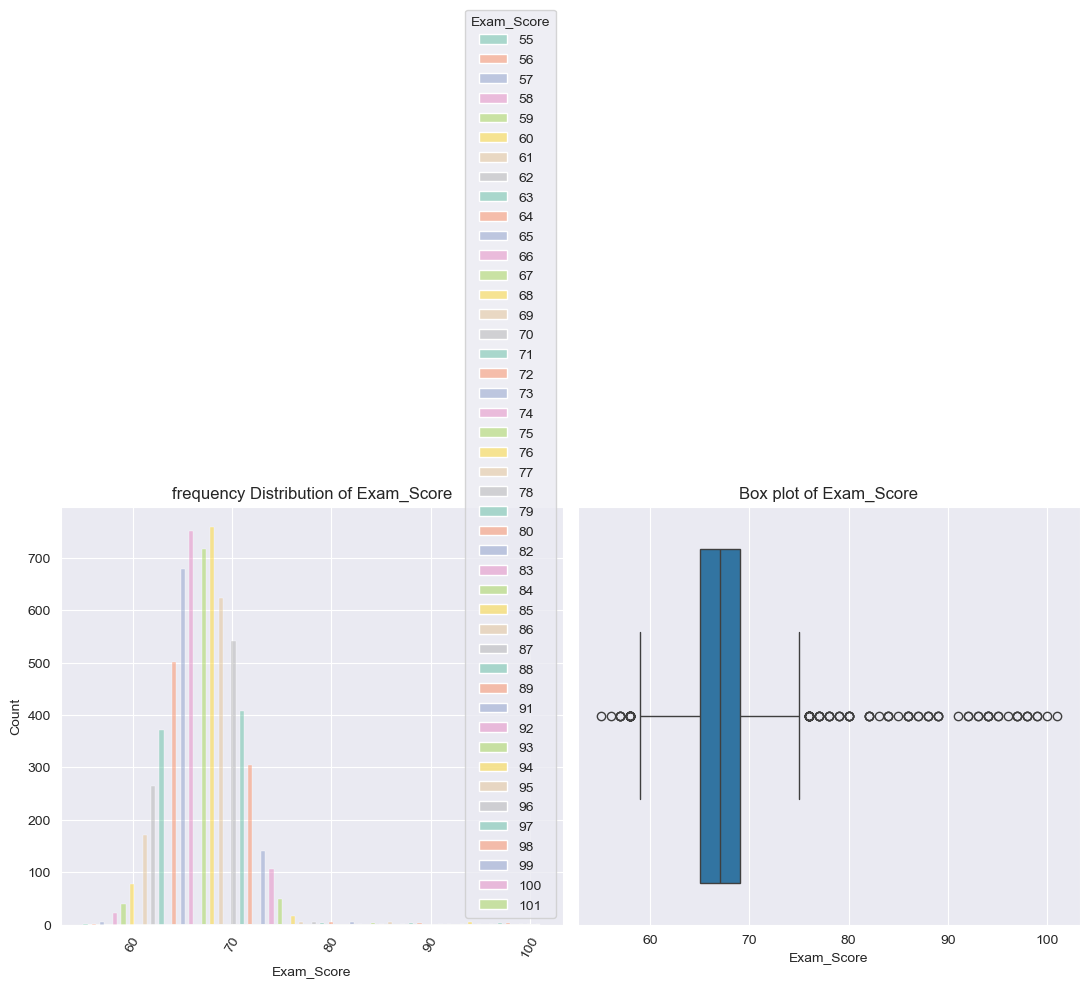

In [15]:
for col in numeric_cols:
    plt.figure(figsize = (11 , 8))
    plt.subplot(1,2,1)
    sns.histplot(data = student_df , x = col , hue = col , palette = 'Set2')
    plt.title(f"frequency Distribution of {col}")
    plt.xticks(rotation = 60)


    plt.subplot(1,2,2)
    sns.boxplot(data = student_df , x = col)
    plt.title(f"Box plot of {col}")
    plt.tight_layout()
    plt.show()

    

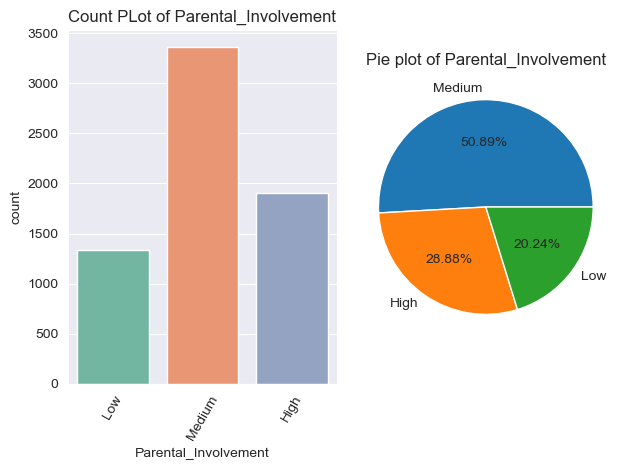

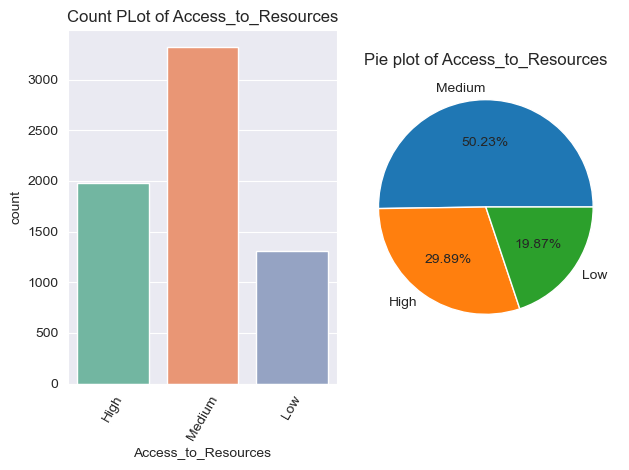

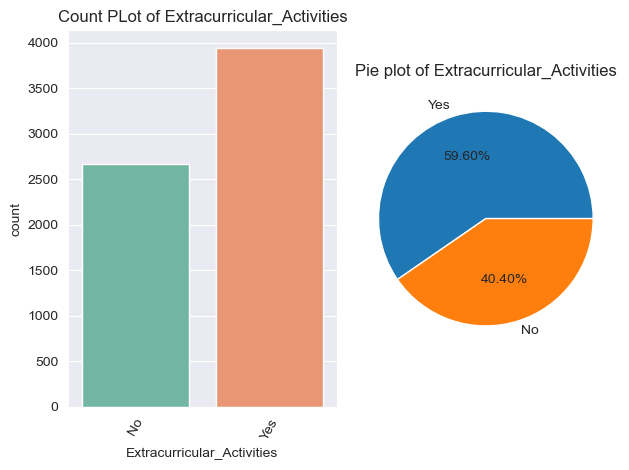

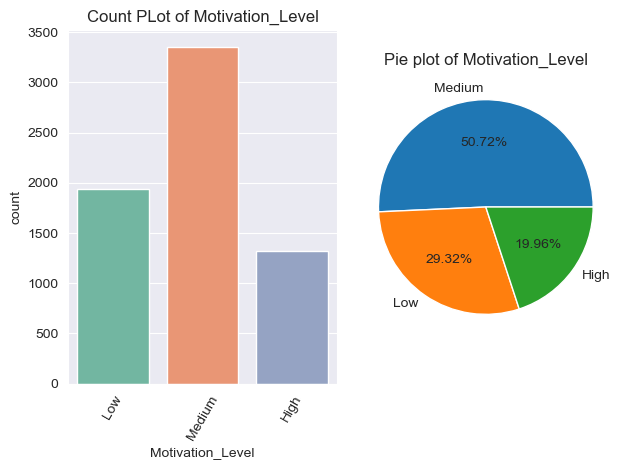

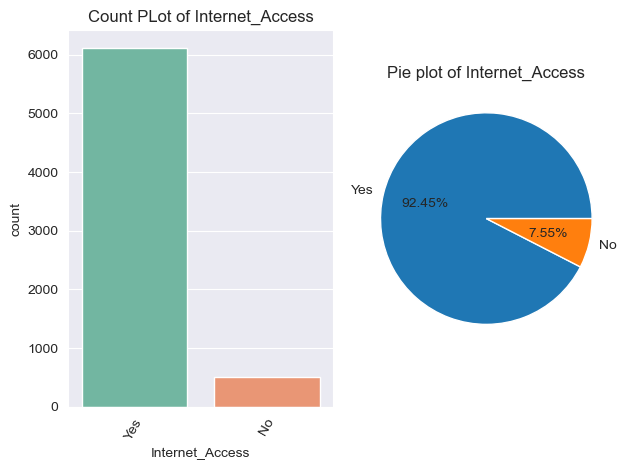

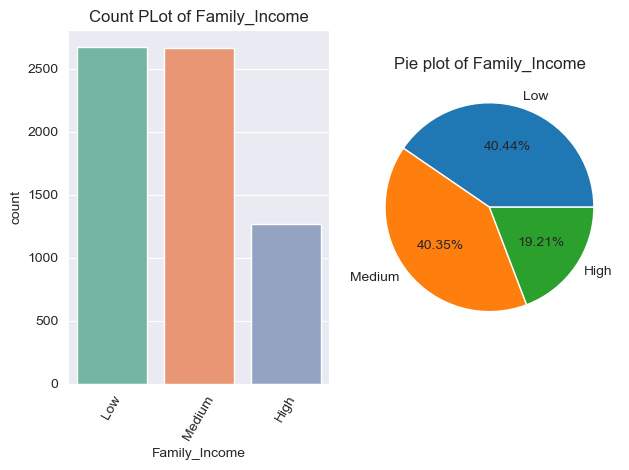

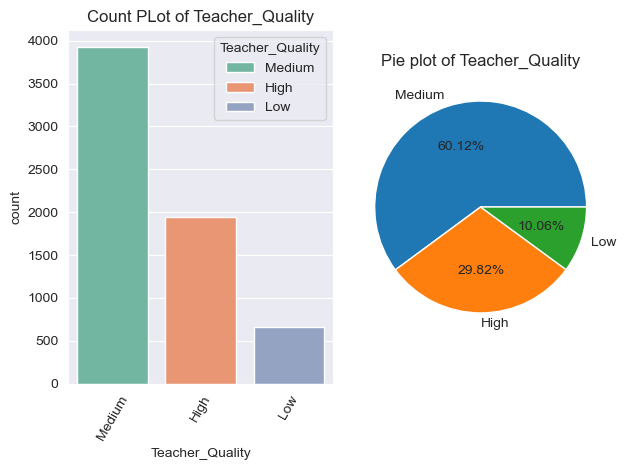

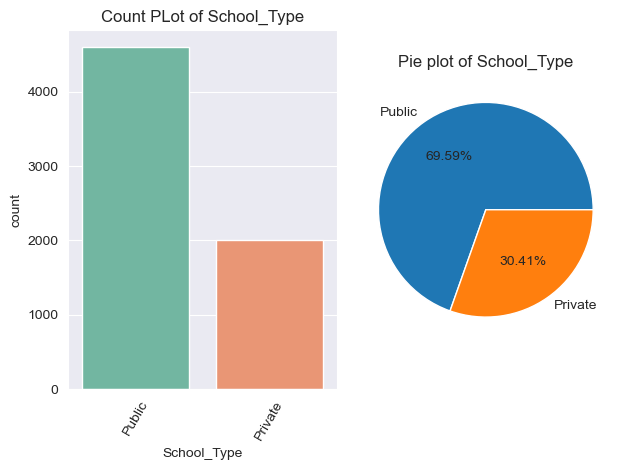

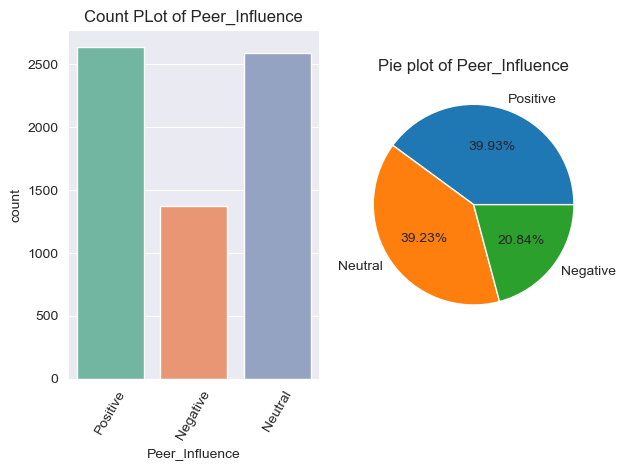

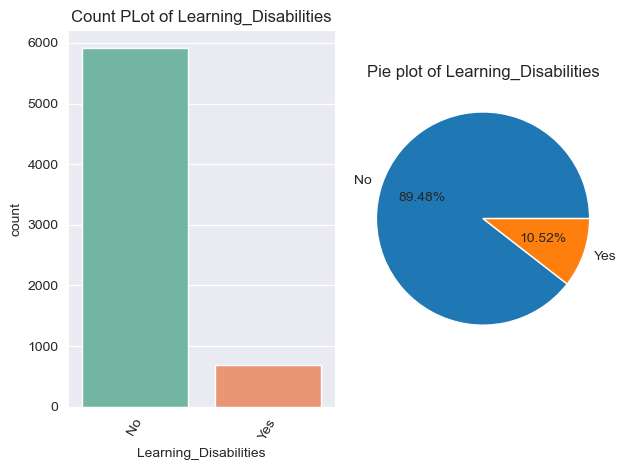

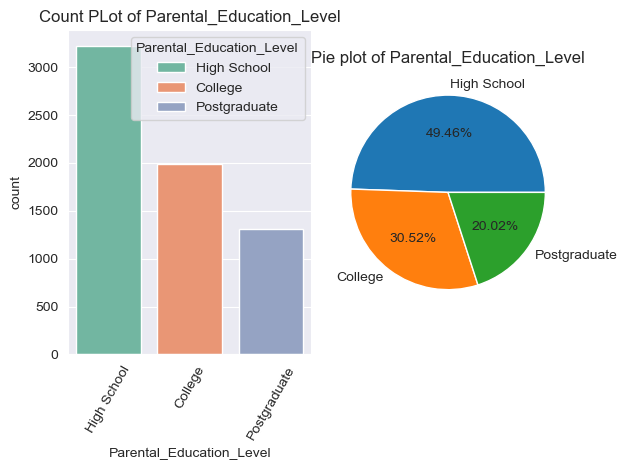

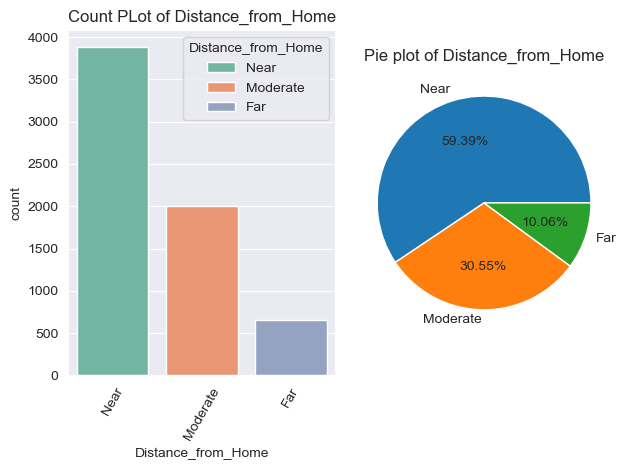

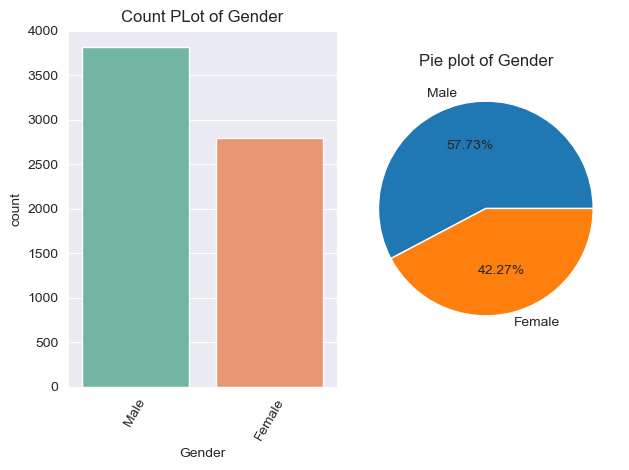

In [16]:
for col in categorical_cols:
    counts = student_df[col].value_counts()
    plt.subplot(1,2,1)
    sns.countplot(data = student_df , x = col , hue = col , palette = 'Set2')
    plt.title(f"Count PLot of {col}")
    plt.xticks(rotation = 60 )

    plt.subplot(1,2,2)
    plt.pie(counts , labels = counts.index , autopct = '%.2f%%')
    plt.title(f"Pie plot of {col}")
    plt.tight_layout()
    plt.show()
    

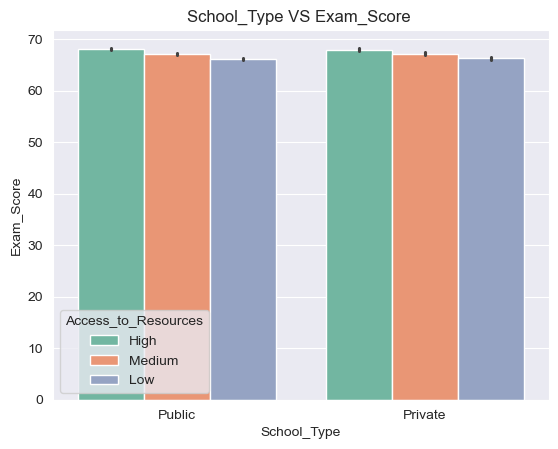

In [17]:
sns.barplot(data = student_df , x = 'School_Type' , y = 'Exam_Score' , hue = 'Access_to_Resources' , palette = 'Set2');
plt.title("School_Type VS Exam_Score ")
plt.show()

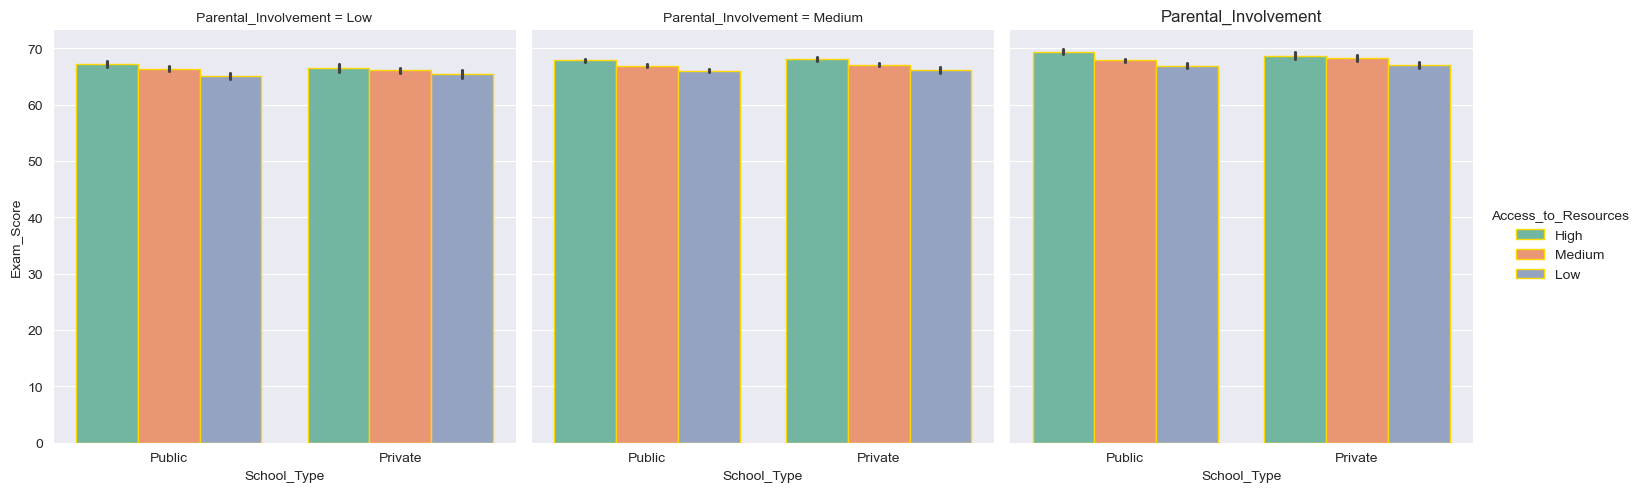

In [18]:
sns.catplot(data = student_df , x = 'School_Type' , y = 'Exam_Score' , hue = 'Access_to_Resources' ,col = 'Parental_Involvement',
            kind = 'bar',
            palette = 'Set2' , ec = 'gold')
plt.title("Parental_Involvement")
plt.show()

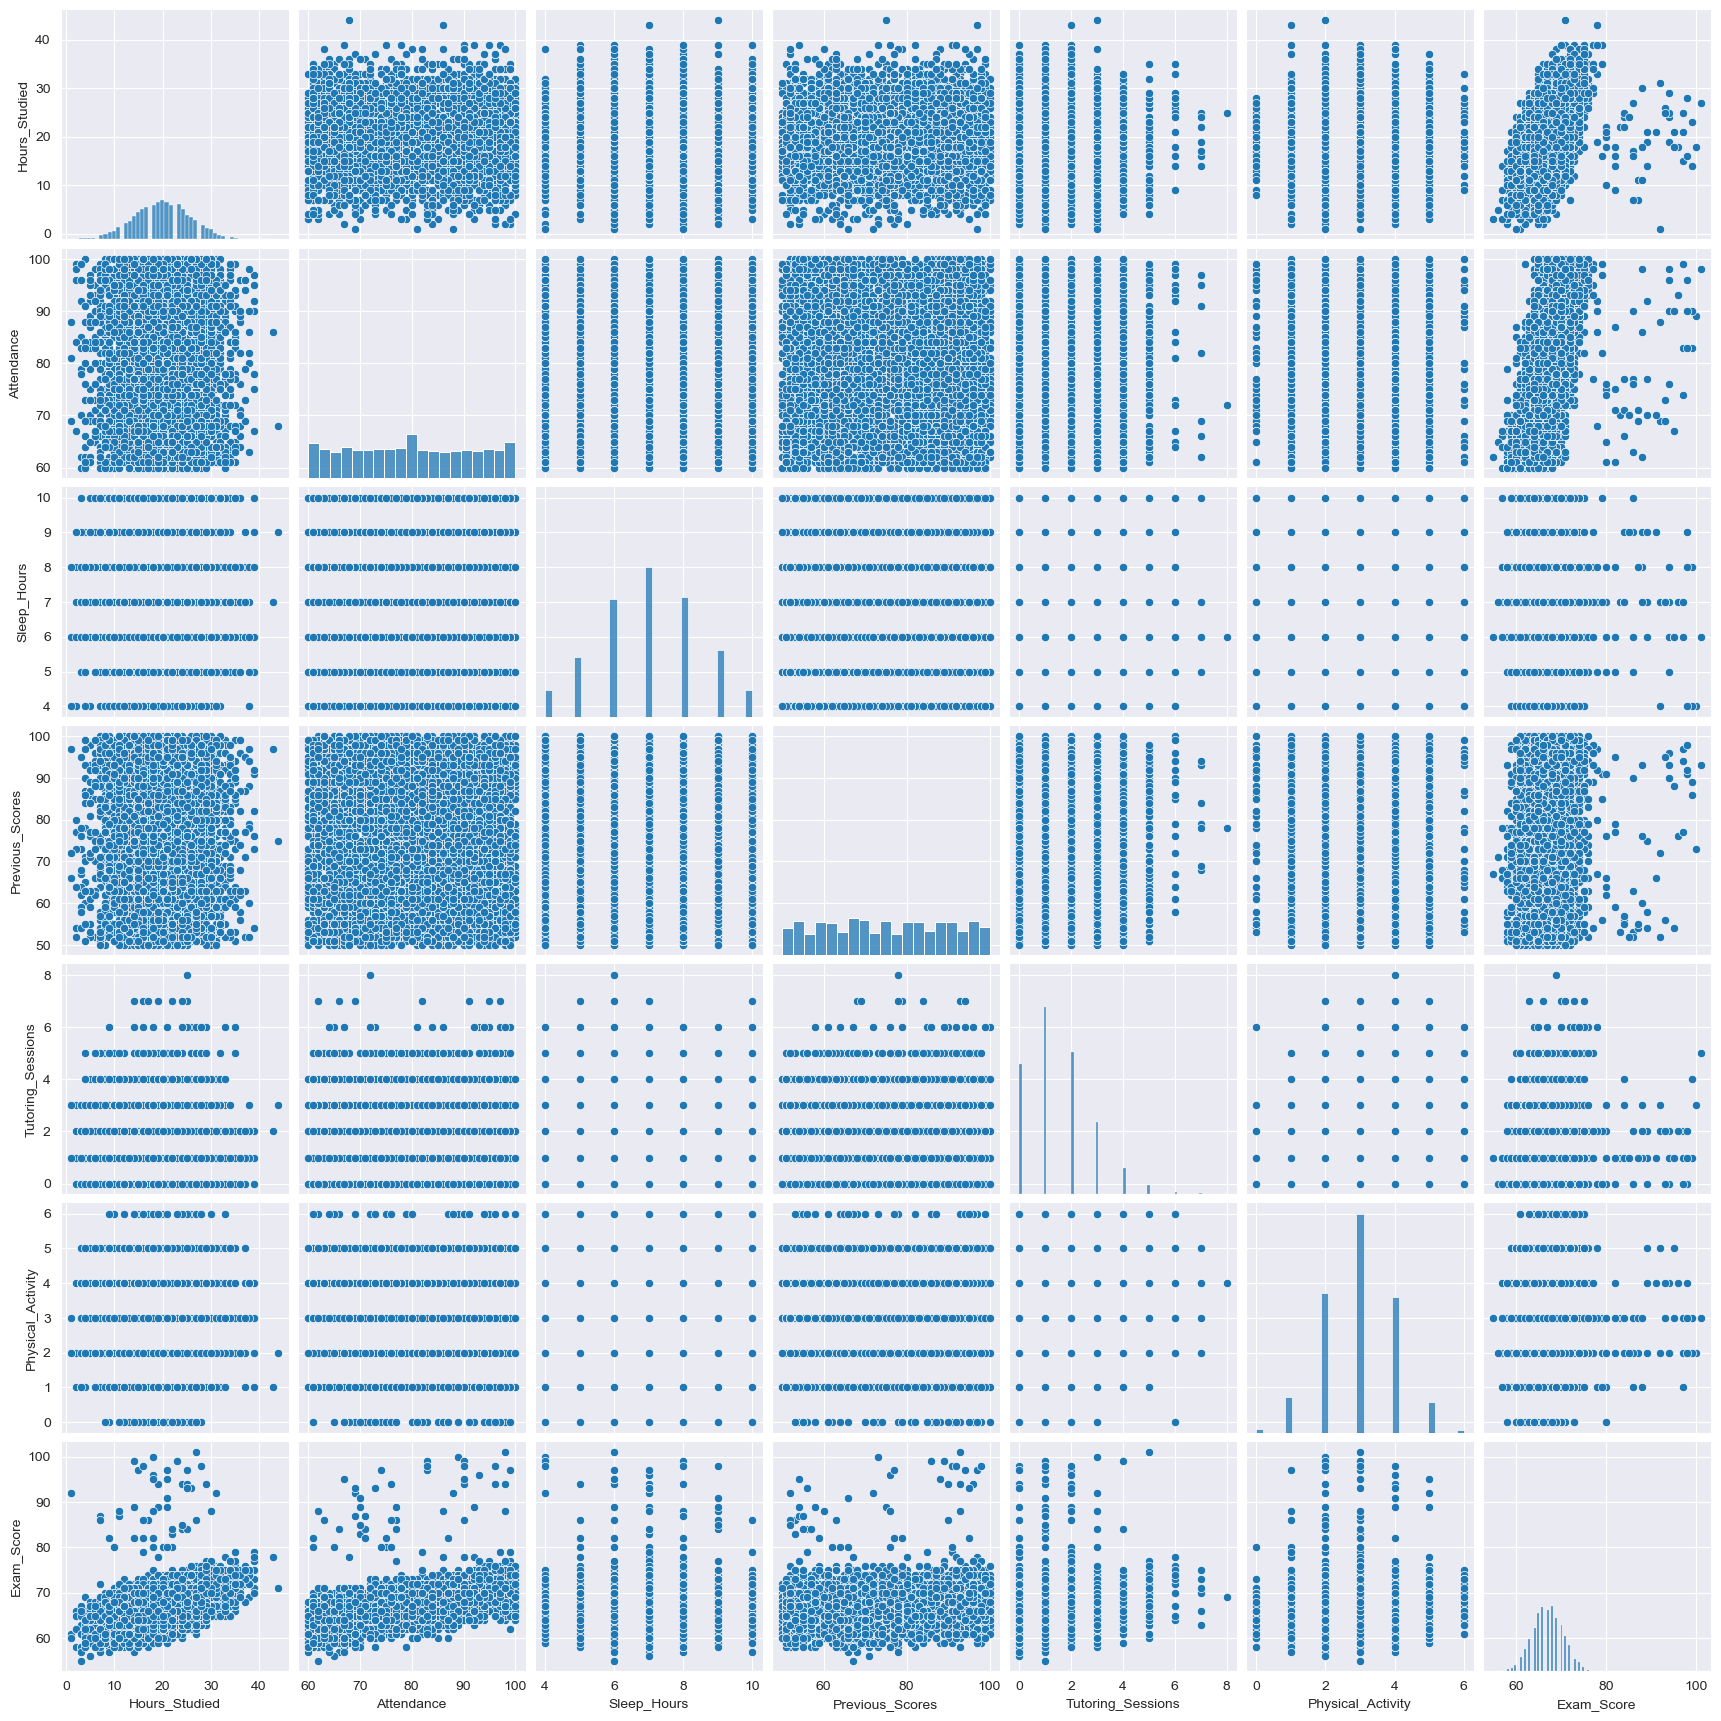

In [19]:
sns.pairplot(student_df)

In [20]:
'''g = sns.PairGrid(student_df[numeric_cols] , palette = 'Set2')
g.map_diag(sns.histplot)
g.map_upper(sns.scatterplot)
g.map_lower(sns.kdeplot)
g.add_legend()'''

"g = sns.PairGrid(student_df[numeric_cols] , palette = 'Set2')\ng.map_diag(sns.histplot)\ng.map_upper(sns.scatterplot)\ng.map_lower(sns.kdeplot)\ng.add_legend()"

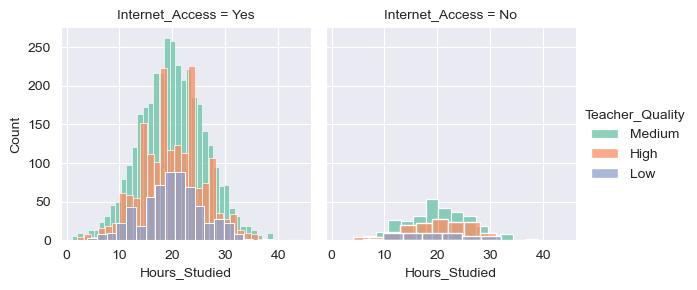

In [21]:
g = sns.FacetGrid(student_df , hue = "Teacher_Quality", col = 'Internet_Access' , palette = 'Set2')
g.map(sns.histplot , 'Hours_Studied')
g.add_legend()

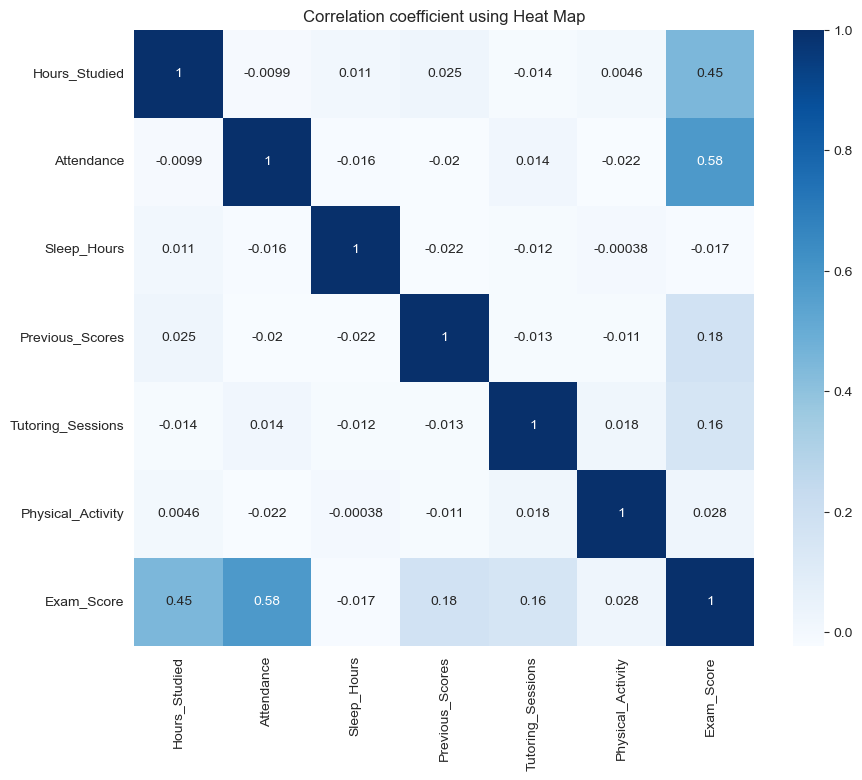

In [22]:
##looking the correlation co-efficient through Heat map
plt.figure(figsize = (10,  8))
sns.heatmap(student_df[numeric_cols].corr(), cmap = 'Blues' , annot = True)
plt.title("Correlation coefficient using Heat Map")
plt.show()

In [23]:
student_df[numeric_cols].corr()['Exam_Score'].sort_values(ascending = False)

Exam_Score           1.000000
Attendance           0.581072
Hours_Studied        0.445455
Previous_Scores      0.175079
Tutoring_Sessions    0.156525
Physical_Activity    0.027824
Sleep_Hours         -0.017022
Name: Exam_Score, dtype: float64

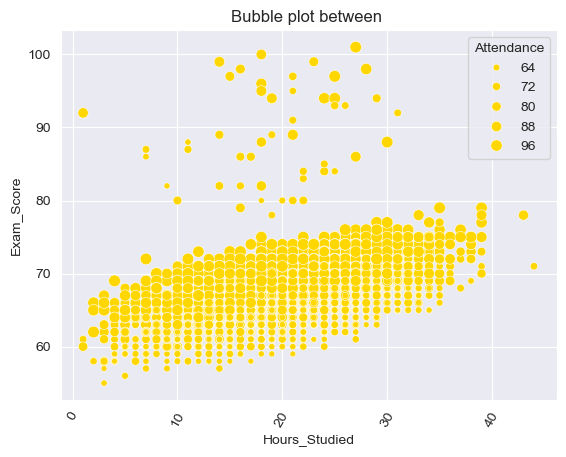

In [24]:
sns.scatterplot(data = student_df , x= 'Hours_Studied' , y = 'Exam_Score' , size = 'Attendance', color = 'gold')
plt.title('Bubble plot between ')
plt.xticks(rotation = 60)
plt.show()

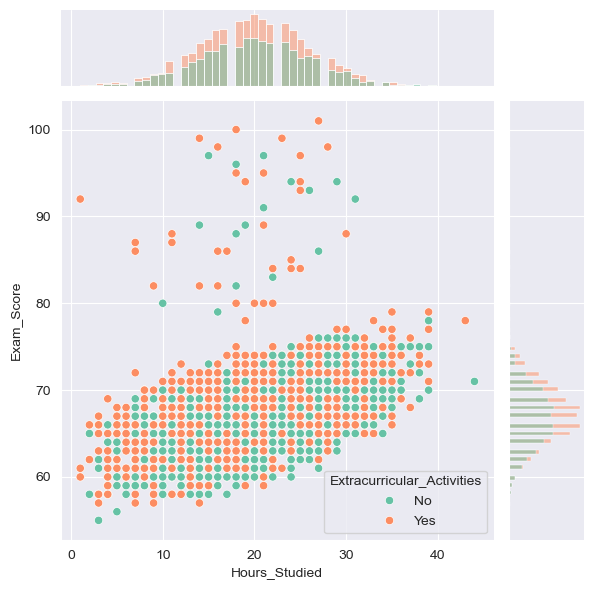

In [25]:
g = sns.JointGrid(data = student_df , x = "Hours_Studied" , y = "Exam_Score" , hue = 'Extracurricular_Activities' , palette = "Set2")
g.plot(sns.scatterplot , sns.histplot)


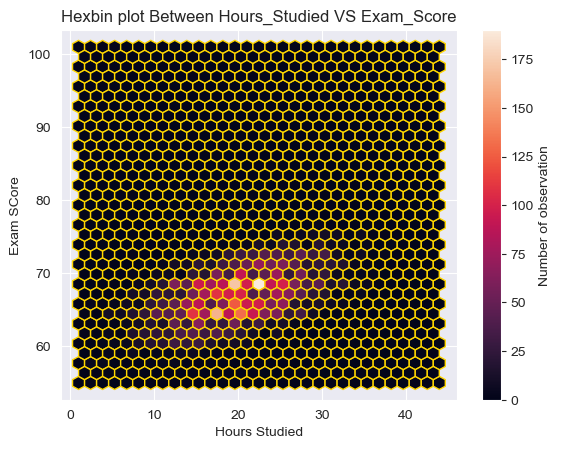

In [26]:
plt.hexbin(x = student_df.Hours_Studied , y = student_df.Exam_Score , gridsize =30 ,color = 'gold' )
plt.colorbar(label= "Number of observation")
plt.title("Hexbin plot Between Hours_Studied VS Exam_Score")
plt.xlabel("Hours Studied")
plt.ylabel("Exam SCore")
plt.show()

In [27]:
student_df.isnull().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [28]:
student_df.shape

(6607, 20)

In [29]:
train_df , val_df = train_test_split(student_df , test_size = 0.1 , random_state = 42)
len(train_df) , len(val_df)


(5946, 661)

In [30]:
input_col = student_df.columns[:-1].tolist()
print(input_col)

['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


In [31]:
input_col = student_df.columns[:-1].tolist()
target_col = 'Exam_Score'
train_input = student_df[input_col]
train_target = student_df[target_col]
val_input = student_df[input_col]
val_target = student_df[target_col]


In [32]:
numeric_cols = train_input.select_dtypes(include = np.number).columns.tolist()
categorical_cols = train_input.select_dtypes(include = 'object').columns.tolist()

In [33]:
len(train_input) , len(train_target)

(6607, 6607)

In [34]:
imputer = SimpleImputer(strategy = 'most_frequent').fit(train_input[categorical_cols])
train_input[categorical_cols] = imputer.transform(train_input[categorical_cols])
val_input[categorical_cols] = imputer.transform(val_input[categorical_cols])


In [35]:
train_input.isna().sum()

Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
dtype: int64

In [36]:
trans = PowerTransformer(method = 'yeo-johnson', standardize = True).fit(train_input[numeric_cols])
train_input[numeric_cols] = trans.transform(train_input[numeric_cols])
val_input[numeric_cols] = trans.transform(val_input[numeric_cols])

In [37]:
train_input[categorical_cols]

,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Motivation_Level,Internet_Access,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
0,Low,High,No,Low,Yes,Low,Medium,Public,Positive,No,High School,Near,Male
1,Low,Medium,No,Low,Yes,Medium,Medium,Public,Negative,No,College,Moderate,Female
2,Medium,Medium,Yes,Medium,Yes,Medium,Medium,Public,Neutral,No,Postgraduate,Near,Male
3,Low,Medium,Yes,Medium,Yes,Medium,Medium,Public,Negative,No,High School,Moderate,Male
4,Medium,Medium,Yes,Medium,Yes,Medium,High,Public,Neutral,No,College,Near,Female
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,High,Medium,No,Medium,Yes,High,Medium,Public,Positive,No,High School,Near,Female
6603,High,Medium,No,Medium,Yes,Low,High,Public,Positive,No,High School,Near,Female
6604,Medium,Low,Yes,Low,Yes,Low,Medium,Public,Negative,No,Postgraduate,Near,Female
6605,High,High,Yes,High,Yes,Low,Medium,Private,Positive,No,High School,Far,Female


In [38]:
categories = [
    ['Low', 'Medium', 'High'],          # Parental_Involvement
    ['Low', 'Medium', 'High'],          # Access_to_Resources
    ['No', 'Yes'],                      # Extracurricular_Activities
    ['Low', 'Medium', 'High'],          # Motivation_Level
    ['No', 'Yes'],                      # Internet_Access
    ['Low', 'Medium', 'High'],          # Family_Income
    ['Low', 'Medium', 'High'],          # Teacher_Quality
    ['Private', 'Public'],              # School_Type
    ['Negative', 'Neutral', 'Positive'],# Peer_Influence
    ['No', 'Yes'],                      # Learning_Disabilities
    ['High School', 'College', 'Postgraduate'], # Parental_Education_Level
    ['Near', 'Moderate', 'Far'],        # Distance_from_Home
    ['Male', 'Female']                  # Gender
]

encoder = OrdinalEncoder(
    categories=categories,
    handle_unknown='use_encoded_value',
    unknown_value=-1,
    encoded_missing_value=-1
)

encoder.fit(train_input[categorical_cols])

train_input[categorical_cols] = encoder.transform(
    train_input[categorical_cols]
)

val_input[categorical_cols] = encoder.transform(
    val_input[categorical_cols]
)

In [39]:
train_input[categorical_cols]

,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Motivation_Level,Internet_Access,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
0,0.0,2.0,0.0,0.0,1.0,0.0,1.0,1.0,2.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0
2,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,2.0,0.0,0.0
3,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
4,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,0.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,2.0,1.0,0.0,1.0,1.0,2.0,1.0,1.0,2.0,0.0,0.0,0.0,1.0
6603,2.0,1.0,0.0,1.0,1.0,0.0,2.0,1.0,2.0,0.0,0.0,0.0,1.0
6604,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,2.0,0.0,1.0
6605,2.0,2.0,1.0,2.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,2.0,1.0


In [42]:
train_input

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
0,0.506583,0.366931,0.0,2.0,0.0,-0.017943,-0.121229,0.0,1.0,-1.468240,0.0,1.0,1.0,2.0,0.027908,0.0,0.0,0.0,0.0
1,-0.160073,-1.404240,0.0,1.0,0.0,0.662257,-1.120018,0.0,1.0,0.572748,1.0,1.0,1.0,0.0,1.001864,0.0,1.0,1.0,1.0
2,0.672922,1.530602,1.0,1.0,1.0,-0.017943,1.099906,1.0,1.0,0.572748,1.0,1.0,1.0,1.0,1.001864,0.0,2.0,0.0,0.0
3,1.502916,0.788821,0.0,1.0,1.0,0.662257,1.559147,1.0,1.0,-0.235072,1.0,1.0,1.0,0.0,1.001864,0.0,0.0,1.0,0.0
4,-0.160073,1.038503,1.0,1.0,1.0,-0.699839,-0.685906,1.0,1.0,1.188471,1.0,2.0,1.0,1.0,1.001864,0.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,0.839141,-0.947427,2.0,1.0,0.0,-0.017943,0.086763,1.0,1.0,-0.235072,2.0,1.0,1.0,2.0,-0.939633,0.0,0.0,0.0,1.0
6603,0.506583,-0.324319,2.0,1.0,0.0,0.662257,0.429242,1.0,1.0,1.188471,0.0,2.0,1.0,2.0,-0.939633,0.0,0.0,0.0,1.0
6604,0.006798,0.872328,1.0,0.0,1.0,-0.699839,-0.685906,0.0,1.0,1.188471,0.0,1.0,1.0,0.0,-0.939633,0.0,2.0,0.0,1.0
6605,-1.669849,0.536575,2.0,2.0,1.0,-0.699839,1.099906,2.0,1.0,0.572748,0.0,1.0,0.0,2.0,0.027908,0.0,0.0,2.0,1.0


In [44]:
def metrics(preds , target):
    rmse = root_mean_squared_error(preds , target) 
    mae = mean_absolute_error(preds , target)
    r2 = r2_score(preds , target)
    print("RMSE: ",rmse) 
    print("MAE: ",mae)
    print("R2 SCore: ", r2)

In [47]:
def try_model(model):
    model.fit(train_input , train_target)
    train_preds = model.predict(train_input)
    val_preds = model.predict(val_input)
    print("TRaining Metrics")
    metrics(train_preds , train_target)
    print('validation Metrics')
    metrics(val_preds , val_target)
    
    
    

In [48]:
try_model(ExtraTreesRegressor(random_state = 42))

TRaining Metrics
RMSE:  0.0
MAE:  0.0
R2 SCore:  1.0
validation Metrics
RMSE:  0.0
MAE:  0.0
R2 SCore:  1.0


In [49]:
try_model(LinearRegression())

TRaining Metrics
RMSE:  2.0370521836331905
MAE:  0.49862919049195864
R2 SCore:  0.6222080226544442
validation Metrics
RMSE:  2.0370521836331905
MAE:  0.49862919049195864
R2 SCore:  0.6222080226544442


Conclusion:

* `ExtraTreesRegressor` has a great numbers in the rmse , mae and r2_score
* Than compare to any other `Linear` model 